In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,StandardScaler,MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,roc_curve,roc_auc_score

In [ ]:
df = pd.read_csv('/content/mushrooms.csv')
print('Dataset loaded successfull')

Dataset loaded successfull


In [ ]:
df.shape

(8124, 23)

In [ ]:
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [ ]:
df.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


In [ ]:
df.isnull().sum()

,0
class,0
cap-shape,0
cap-surface,0
cap-color,0
bruises,0
odor,0
gill-attachment,0
gill-spacing,0
gill-size,0
gill-color,0


In [ ]:
#Check duplicate records
print("number of duplicates :",df.duplicated().sum())

number of duplicates : 0


In [ ]:
df.replace('?', np.nan, inplace=True)
print("Replaced '?' with NaN values.")

Replaced '?' with NaN values.


In [ ]:
# Fill the Missing values in 'stalk-root' (corrected order)
df['stalk-root'] = df['stalk-root'].fillna(df['stalk-root'].mode()[0])
print("Filled missing values in 'stalk-root'.")


Filled missing values in 'stalk-root'.


In [ ]:
# LabelEncoder
le = LabelEncoder()
df['class'] = le.fit_transform(df['class'])
print("Label encoded 'class' column.")

Label encoded 'class' column.


In [ ]:
# One-hot Encoding
categorical_cols = ['cap-shape','cap-surface','cap-color','bruises',
        'odor','gill-attachment','gill-spacing','gill-size','gill-color','stalk-shape',
        'stalk-root','stalk-surface-above-ring','stalk-surface-below-ring',
        'stalk-color-above-ring','stalk-color-below-ring','veil-type','veil-color',
        'ring-number','ring-type','spore-print-color','population','habitat']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print("Applied one-hot encoding to categorical columns.")

Applied one-hot encoding to categorical columns.


In [ ]:
df.head(5)

,class,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_g,cap-surface_s,cap-surface_y,cap-color_c,...,population_n,population_s,population_v,population_y,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,1,False,False,False,False,True,False,True,False,False,...,False,True,False,False,False,False,False,False,True,False
1,0,False,False,False,False,True,False,True,False,False,...,True,False,False,False,True,False,False,False,False,False
2,0,False,False,False,False,False,False,True,False,False,...,True,False,False,False,False,False,True,False,False,False
3,1,False,False,False,False,True,False,False,True,False,...,False,True,False,False,False,False,False,False,True,False
4,0,False,False,False,False,True,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False


In [ ]:
#identify x and y
x = df.drop('class', axis=1)
y = df['class']

In [ ]:
#split the dataset into training and testing
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
scaler = StandardScaler()
cols_to_scale = x_train.columns
x_train[cols_to_scale] = scaler.fit_transform(x_train[cols_to_scale])
x_test[cols_to_scale] = scaler.transform(x_test[cols_to_scale])
print("First 2 rows of scaled x_train data : ")
print(x_train.head(2))

First 2 rows of scaled x_train data : 
      cap-shape_c  cap-shape_f  cap-shape_k  cap-shape_s  cap-shape_x  \
5249    -0.024816     1.257793    -0.334216     -0.06459    -0.908040   
5781    -0.024816    -0.795044    -0.334216     -0.06459     1.101273   

      cap-surface_g  cap-surface_s  cap-surface_y  cap-color_c  cap-color_e  \
5249       -0.02149      -0.678806       1.236444    -0.073584    -0.471006   
5781       -0.02149       1.473175      -0.808771    -0.073584    -0.471006   

      ...  population_n  population_s  population_v  population_y  habitat_g  \
5249  ...     -0.232759     -0.423917     -0.990353      1.920686   1.660970   
5781  ...     -0.232759     -0.423917     -0.990353     -0.520647  -0.602058   

      habitat_l  habitat_m  habitat_p  habitat_u  habitat_w  
5249  -0.336204  -0.191974  -0.398598  -0.220373  -0.157339  
5781  -0.336204  -0.191974  -0.398598  -0.220373   6.355699  

[2 rows x 94 columns]


In [ ]:
#Model Building
model = LogisticRegression()
model.fit(x_train,y_train)

LogisticRegression()

In [ ]:
#Predictions on test data
y_pred = model.predict(x_test)

In [ ]:
#Testing and TrainingAccuracy
train_accuracy=model.score(x_train,y_train)
test_accuracy=model.score(x_test,y_test)
print("Training Accuracy:",train_accuracy)
print("Testing Accuracy:",test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 1.0


In [ ]:
#confusion matrix
conf_mat=confusion_matrix(y_test,y_pred)
print("Confusion Matrix :")
print(conf_mat)

Confusion Matrix :
[[842   0]
 [  0 783]]


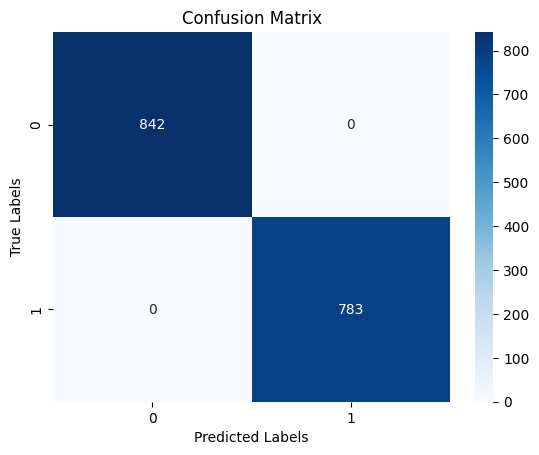

In [ ]:
#Display confusion matrix
sns.heatmap(conf_mat,annot=True,fmt='d',cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [ ]:
#print classification report
class_report=classification_report(y_test,y_pred,target_names=['Edible','Poisonous'])
print("Classification Report :",class_report)

Classification Report :               precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [ ]:
#Probability predictions
y_pred_prob=model.predict_proba(x_test)[:,1]
#auc_roc_curve and auc_score
fpr,tpr,thresholds=roc_curve(y_test,y_pred_prob)
auc_score=roc_auc_score(y_test,y_pred_prob)
print('AUC Score :',auc_score)

AUC Score : 1.0


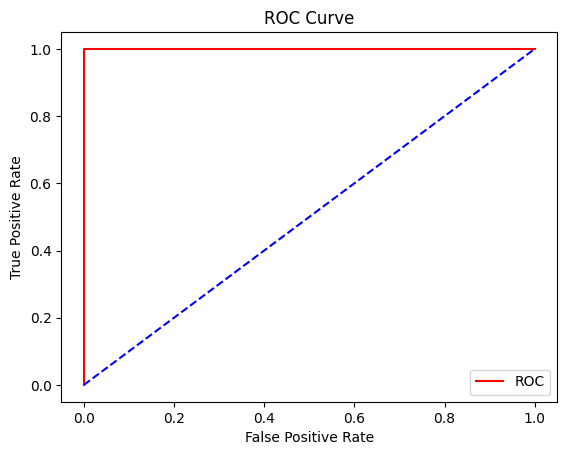

In [ ]:
#Display auc_roc_curve
plt.plot(fpr,tpr,color='red',label='ROC')
plt.plot([0,1],[0,1],color='blue',linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()